In [7]:
import numpy as np
import  pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import os
import torch, torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import IPython.display as ipd
import random
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit

# Data Loading Pipeline

In [2]:
BASE = "/kaggle/input/competitions/birdclef-2025"  # <-- CHANGE THIS to what FOUND printed
# example: BASE = "/kaggle/input/birdclef-2025/birdclef-2025" if needed

train = pd.read_csv(f"{BASE}/train.csv")
taxonomy = pd.read_csv(f"{BASE}/taxonomy.csv")
print(BASE, train.shape)

/kaggle/input/competitions/birdclef-2025 (28564, 13)


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
sample_df=train.sample(frac=0.1,random_state=42)

In [5]:
sample_df.shape

(2856, 13)

In [6]:
sample_df.head()

,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
27685,yeofly1,[''],['call'],yeofly1/XC250351.ogg,XC,4.0,https://xeno-canto.org/250351,-4.4010,-79.8540,Tolmomyias sulphurescens,Yellow-olive Flycatcher,Niels Krabbe,cc-by-sa 4.0
25019,whbman1,[''],['mechanical sounds'],whbman1/XC268585.ogg,XC,5.0,https://xeno-canto.org/268585,-19.7323,-41.8141,Manacus manacus,White-bearded Manakin,Fabrice Schmitt,cc-by-nc-sa 4.0
96,21211,[''],[''],21211/XC913998.ogg,XC,3.0,https://xeno-canto.org/913998,4.0946,-52.6862,Allobates femoralis,Spotted-thighed Poison Frog,Delaitre guillaume,cc-by-nc-sa 4.0
5771,bugtan,[''],['flight call'],bugtan/XC480423.ogg,XC,5.0,https://xeno-canto.org/480423,-0.4383,-76.2791,Thraupis episcopus,Blue-gray Tanager,Jerome Fischer,cc-by-nc-sa 4.0
21879,strher,"['greani1', 'grekis']",['flight call'],strher/XC287867.ogg,XC,3.5,https://xeno-canto.org/287867,-22.4508,-42.7735,Butorides striata,Striated Heron,Jerome Fischer,cc-by-nc-sa 4.0


In [8]:
# Label map
labels = sorted(train['primary_label'].unique())
label2idx = {l:i for i,l in enumerate(labels)}
idx2label = {i:l for l,i in label2idx.items()}
print(f"Num classes: {len(labels)}")

class CFG:
    SR = 32000       # Sample rate (32kHz)
    DURATION = 5     # Every clip is fixed at 5 seconds
    N_MELS = 128     # 128 Mel frequency bins
    BATCH = 32       # Batch size

class BirdDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_mels=CFG.N_MELS, f_min=50, f_max=14000, n_fft=1024, hop_length=512
        )
        self.db = torchaudio.transforms.AmplitudeToDB()
        
    def __len__(self): return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = os.path.join(BASE, "train_audio", row['filename'])
        
        wav, sr = torchaudio.load(path)
        wav = wav.mean(dim=0) # mono
        
        # crop/pad to 5 sec
        if sr != CFG.SR:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=CFG.SR)
            wav = resampler(wav)
            
        target = CFG.SR * CFG.DURATION
        if len(wav) > target:
            start = torch.randint(0, len(wav)-target, (1,)).item()
            wav = wav[start:start+target]
        else:
            wav = F.pad(wav, (0, target - len(wav)))
            
        mel = self.mel(wav)
        mel = self.db(mel)
        mel = (mel - mel.mean()) / (mel.std() + 1e-6)
        
        label = label2idx[row['primary_label']]
        return mel, label


Num classes: 206


In [11]:
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

In [16]:
counts = sample_df['primary_label'].value_counts()
rare_classes = counts[counts == 1].index

In [18]:
rare_classes.shape

(21,)

In [17]:
for i in rare_classes:
    print(i)

555086
spbwoo1
1194042
rosspo1
66531
1564122
65962
woosto
21116
963335
81930
65344
piwtyr1
566513
grysee1
555142
46010
plctan1
65419
22333
1462737


In [21]:
sample_df = sample_df[~sample_df['primary_label'].isin(rare_classes)].reset_index(drop=True)

In [22]:
sample_df.shape

(2835, 13)

In [23]:
train_idx, val_idx = next(splitter.split(sample_df, sample_df['primary_label']))

In [25]:
train_idx

array([ 539, 2806, 1330, ..., 2356, 2226,  837])

In [24]:
train_df = sample_df.iloc[train_idx].reset_index(drop=True)
val_df = sample_df.iloc[val_idx].reset_index(drop=True)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)}")

Train size: 2268 | Val size: 567


In [26]:
train_dataset=BirdDataset(train_df)
val_dataset=BirdDataset(val_df)

In [27]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [28]:
mels, labs = next(iter(train_loader))
print("Batch shape:", mels.shape)       
print("Labels shape:", labs.shape)

Batch shape: torch.Size([32, 128, 313])
Labels shape: torch.Size([32])


#  The Timm Model

In [30]:
len(label2idx)

206

In [31]:
import timm
import torch

# 1. Define the number of classes (from your label dictionary)
num_classes = len(label2idx)

# 2. Create the model
# in_chans=1 adapts the first conv layer to accept 1 channel (our mel spectrogram)
# num_classes=206 changes the final fully connected layer to output 206 logits
model = timm.create_model(
    'tf_efficientnet_b0', 
    pretrained=True, 
    in_chans=1, 
    num_classes=num_classes
)

# 3. Move to GPU
model = model.to(device)

# 4. Print number of parameters (good habit to check)
total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded with {total_params:,} parameters")

# 5. Sanity check with a dummy tensor
# Create a fake batch of 2 spectrograms (Batch=2, Channels=1, Mel=128, Time=313)
dummy_input = torch.randn(2, 1, 128, 313).to(device)

# Pass it through the model
with torch.no_grad():
    dummy_output = model(dummy_input)

print(f"Dummy input shape: {dummy_input.shape}")
print(f"Dummy output shape: {dummy_output.shape}") # Must be [2, 206]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded with 4,270,858 parameters
Dummy input shape: torch.Size([2, 1, 128, 313])
Dummy output shape: torch.Size([2, 206])


# Loss, Optimizer, Scheduler

In [32]:
import torch.nn as nn
import torch.optim as optim

# 1. Loss Function 
# We use CrossEntropyLoss which expects raw logits and integer targets
criterion = nn.CrossEntropyLoss()

# 2. Optimizer (AdamW is the standard for transformers/CNNs)
# lr=1e-3 is a good starting point for transfer learning
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

# 3. Scheduler (Cosine Annealing)
# T_max=5 means the learning rate will follow a cosine curve over 5 epochs
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

# 4. Mixed Precision Scaler
# This cuts VRAM usage in half and speeds up training on T4 GPUs
# Note: In newer PyTorch versions, it's torch.amp.GradScaler('cuda')
try:
    scaler = torch.amp.GradScaler('cuda')
except AttributeError:
    scaler = torch.cuda.amp.GradScaler() # Fallback for older PyTorch

print("Criterion, Optimizer, Scheduler, and Scaler are ready!")

Criterion, Optimizer, Scheduler, and Scaler are ready!


# The Training Loop

In [34]:
import time

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()
    
    # Loop over the batches
    for batch_idx, (mels, labs) in enumerate(train_loader):
        
        # 1. Move data to GPU
        mels = mels.to(device)
        labs = labs.to(device)
        mels = mels.unsqueeze(1)
        
        # 2. Zero gradients
        optimizer.zero_grad()
        
        # 3. Forward pass with Mixed Precision (Autocast)
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            loss = criterion(outputs, labs)
            
        # 4. Backward pass with Scaler
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        # 5. Track loss
        running_loss += loss.item()
        
        # Print every 10 batches
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}")
            
    # --- END OF EPOCH ---
    # Step the scheduler (Crucial: only once per epoch!)
    scheduler.step()
    
    # Calculate average loss for the epoch
    avg_train_loss = running_loss / len(train_loader)
    end_time = time.time()
    
    print(f"=== Epoch {epoch+1} Complete | Avg Train Loss: {avg_train_loss:.4f} | Time: {end_time - start_time:.1f}s ===")
    print("-" * 50)

/tmp/ipykernel_49/2049029608.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/5] | Batch [10/71] | Loss: 4.9493
Epoch [1/5] | Batch [20/71] | Loss: 5.0554
Epoch [1/5] | Batch [30/71] | Loss: 4.6208
Epoch [1/5] | Batch [40/71] | Loss: 4.4886
Epoch [1/5] | Batch [50/71] | Loss: 4.2800
Epoch [1/5] | Batch [60/71] | Loss: 4.2748
Epoch [1/5] | Batch [70/71] | Loss: 3.9494
=== Epoch 1 Complete | Avg Train Loss: 4.5700 | Time: 74.5s ===
--------------------------------------------------
Epoch [2/5] | Batch [10/71] | Loss: 3.2983
Epoch [2/5] | Batch [20/71] | Loss: 3.1906
Epoch [2/5] | Batch [30/71] | Loss: 3.3612
Epoch [2/5] | Batch [40/71] | Loss: 3.7748
Epoch [2/5] | Batch [50/71] | Loss: 2.8193
Epoch [2/5] | Batch [60/71] | Loss: 3.0693
Epoch [2/5] | Batch [70/71] | Loss: 3.6202
=== Epoch 2 Complete | Avg Train Loss: 3.3068 | Time: 37.5s ===
--------------------------------------------------
Epoch [3/5] | Batch [10/71] | Loss: 2.1597
Epoch [3/5] | Batch [20/71] | Loss: 2.4943
Epoch [3/5] | Batch [30/71] | Loss: 2.3148
Epoch [3/5] | Batch [40/71] | Loss: 2.2

# Validation Loop

In [36]:
# 1. Set model to evaluation mode
model.eval()

correct = 0
total = 0

print("Running validation...")

# 2. No gradients needed for testing
with torch.no_grad():
    for batch_idx, (mels, labs) in enumerate(val_loader):
        mels, labs = mels.to(device), labs.to(device)
        
        # Apply the fix!
        mels = mels.unsqueeze(1) 
        
        # Mixed precision (faster)
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            
        # Get the highest probability class
        preds = outputs.argmax(dim=1)
        
        # Count how many are correct
        correct += (preds == labs).sum().item()
        total += labs.size(0)

# 3. Calculate and print the final accuracy
val_acc = correct / total
print(f"\n✅ Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Correct predictions: {correct} / {total}")

# 4. Save the model weights anyway (so you don't lose them)
torch.save(model.state_dict(), 'efficientnet_b0_baseline.pth')
print("Model saved as 'efficientnet_b0_baseline.pth'")

Running validation...


/tmp/ipykernel_49/160406034.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



✅ Validation Accuracy: 41.27%
Correct predictions: 234 / 567
Model saved as 'efficientnet_b0_baseline.pth'


In [70]:
wav, sr = torchaudio.load(file_path)

In [71]:
wav,sr

(tensor([[-7.0688e-06,  1.2859e-06, -8.4268e-06,  ...,  1.6316e-06,
          -5.7575e-06,  3.5008e-06]]),
 32000)

In [72]:
wav.shape

torch.Size([1, 593664])

In [73]:
wav.mean(dim=0)

tensor([-7.0688e-06,  1.2859e-06, -8.4268e-06,  ...,  1.6316e-06,
        -5.7575e-06,  3.5008e-06])

In [78]:
# Pick a random file from the validation set
# Try changing the 0 to 1, 2, 3 etc. to test different birds
row = val_df.iloc[18] 
file_path = os.path.join(BASE, "train_audio", row['filename'])
true_label_name = row['primary_label']

print(f"Testing File: {row['filename']}")
print(f"True Species: {true_label_name}")

# 1. Load audio for the MODEL
wav, sr = torchaudio.load(file_path)
wav = wav.mean(dim=0) # mono

# --- HEAR THE SOUND ---
# We load it separately here just to play it without the 5-second crop
play_wav, play_sr = librosa.load(file_path, sr=None)
print("\n🔊 Listen to the bird:")
display(ipd.Audio(play_wav, rate=play_sr))
# ----------------------

# 2. Resample if needed
if sr != 32000:
    resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=32000)
    wav = resampler(wav)

# 3. Crop/Pad to 5 seconds (Take the first 5 seconds for testing)
target = 32000 * 5
if len(wav) > target:
    wav = wav[:target] 
else:
    wav = F.pad(wav, (0, target - len(wav)))

# 4. Create MelSpectrogram
mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=32000, n_mels=128, f_min=50, f_max=14000, n_fft=1024, hop_length=512
)
db_transform = torchaudio.transforms.AmplitudeToDB()

mel = mel_transform(wav)
mel = db_transform(mel)
mel = (mel - mel.mean()) / (mel.std() + 1e-6)

# 5. Prepare for model
mel = mel.unsqueeze(0).unsqueeze(0).to(device) # Shape: (1, 1, 128, 313)

# 6. Predict
model.eval()
with torch.no_grad():
    with torch.cuda.amp.autocast():
        outputs = model(mel)
        pred_idx = outputs.argmax(dim=1).item()

pred_label_name = idx2label[pred_idx]

print(f"\nModel Prediction: {pred_label_name}")
if pred_label_name == true_label_name:
    print("✅ Model got it RIGHT!")
else:
    print("❌ Model got it WRONG.")

Testing File: amekes/XC681907.ogg
True Species: amekes

🔊 Listen to the bird:



Model Prediction: linwoo1
❌ Model got it WRONG.


/tmp/ipykernel_49/1891485734.py:49: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


In [74]:
mel

tensor([[[[-2.0147, -2.6606, -2.6606,  ..., -0.7491, -0.2011,  0.3437],
          [-2.6488, -2.6606, -2.6606,  ..., -0.4761, -0.1948,  0.2370],
          [-2.6606, -2.6606, -2.6606,  ..., -0.5031, -0.2218,  0.2100],
          ...,
          [-1.3222, -1.3503, -1.3150,  ..., -2.5156, -2.6606,  0.2465],
          [-1.2244, -1.2107, -1.2942,  ..., -2.5433, -2.6606,  0.2438],
          [-1.1974, -1.3400, -1.3032,  ..., -2.5102, -2.6606,  0.2413]]]],
       device='cuda:0')

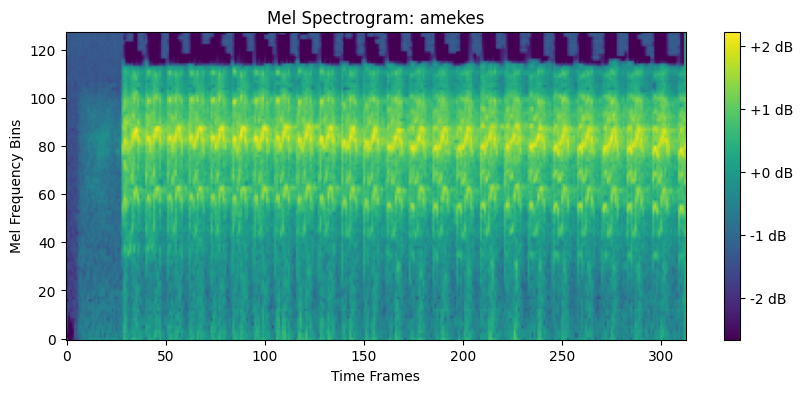

In [79]:
import matplotlib.pyplot as plt

# 1. Remove batch/channel dimensions, move from GPU to CPU, and convert to numpy
mel_np = mel.squeeze().cpu().numpy()

# 2. Plot the 2D grid as an image
plt.figure(figsize=(10, 4))
plt.imshow(mel_np, aspect="auto", origin="lower", cmap="viridis")
plt.colorbar(format="%+2.0f dB")
plt.title(f"Mel Spectrogram: {true_label_name}")
plt.xlabel("Time Frames")
plt.ylabel("Mel Frequency Bins")
plt.show()

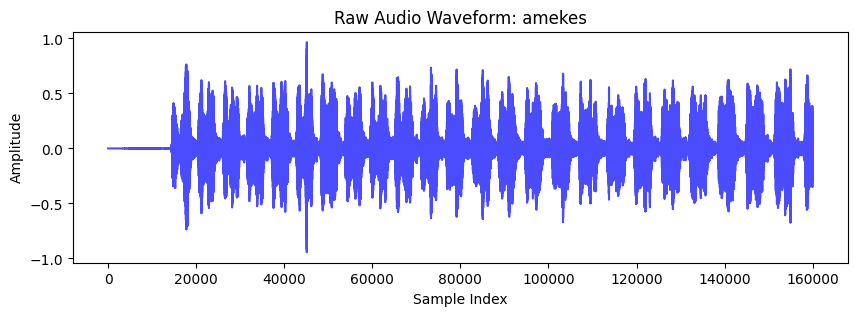

In [80]:
import matplotlib.pyplot as plt

# Plot the 1D raw waveform tensor
plt.figure(figsize=(10, 3))
plt.plot(wav.numpy(), alpha=0.7, color="b")
plt.title(f"Raw Audio Waveform: {true_label_name}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.show()